# Segmentation Model


### 1. import packages

In [70]:
# NOTE from Hanan:
# This cell does not contain any mistake.
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models

### 2. PATH

In [71]:
# NOTE from Hanan:
# This cell does not contain any  mistake.

BASE_DIR = "weizmann_horse_db"

IMAGE_DIR = os.path.join(BASE_DIR, "horse")
MASK_DIR = os.path.join(BASE_DIR, "mask")

IMG_SIZE = (128, 128)

### 3. statics

In [72]:
image_files = sorted(os.listdir(IMAGE_DIR))
mask_files = sorted(os.listdir(MASK_DIR))

print("Number of images:", len(image_files))
print("Number of masks:", len(mask_files))

print("First image:", image_files[0])
#====================================
print("First mask:", mask_files[0]) # It had a mistake and was corrected.
#====================================

Number of images: 327
Number of masks: 327
First image: horse001.png
First mask: horse001.png


### 4. Read image

1. created path
2. open image (RGB) and resize and normaliz
3. change type to float32
4. standatd for learning
5. create images and masks

In [73]:
# NOTE from Hanan:
# This cell does not contain any  mistake.

images = []
masks = []

for img_name in image_files:
    # path
    img_path = os.path.join(IMAGE_DIR, img_name)
    mask_path = os.path.join(MASK_DIR, img_name)

    # open (RGB) - resize 128*128 - normalaizer
    img = Image.open(img_path).convert("RGB")
    img = img.resize(IMG_SIZE)
    img = np.array(img) / 255.0

    # open (RGB) - resize 128*128 - normalaizer
    mask = Image.open(mask_path).convert("L")
    mask = mask.resize(IMG_SIZE)
    mask = np.array(mask)

    # change type
    mask = (mask > 0).astype(np.float32)

    # standatd for learning
    mask = np.expand_dims(mask, axis=-1)

    images.append(img)
    masks.append(mask)

images = np.array(images, dtype=np.float32)
masks = np.array(masks, dtype=np.float32)

print("Images shape:", images.shape)
print("Masks shape:", masks.shape)

Images shape: (327, 128, 128, 3)
Masks shape: (327, 128, 128, 1)


### 5. show 1st image by mask

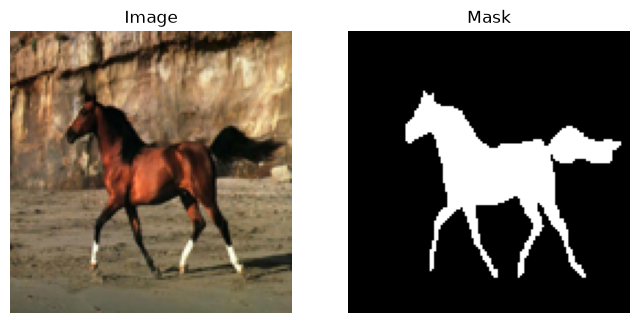

In [74]:
# NOTE from Hanan:
# This cell does not contain any  mistake.

index = 0

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(images[index])
plt.title("Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(masks[index].squeeze(), cmap="gray")
plt.title("Mask")
plt.axis("off")

plt.show()

### 6. Use train_test_split

create train and test by `train_test_split` method

standard selectin is 80%-20%

we have 327 images

We have few images, and it is not rational to set aside 50 percent for testing.

In [75]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    images,
    masks,
    test_size=0.2, # edited to 0.2 or 20%
    random_state=42
)

print("Train images:", X_train.shape)
#=====================================
print("Test images:", X_test.shape)
#=====================================

Train images: (261, 128, 128, 3)
Test images: (66, 128, 128, 3)


### 7. create Model

The images are in RGB format, so they have 3 channels, and the input dimensions should be $128 \times 128 \times 3$.

Ignore `x = layers.Flatten()(x)`

change change  `relu` to `sigmoid`  in `outputs`


In [76]:
#=============================================================
def build_simple_segmentation_model(input_shape=(128, 128, 3)): # image has 3 chanals
    #=========================================================
    inputs = layers.Input(shape=input_shape)

    # Encoder
    x = layers.Conv2D(16, 3, padding="same", activation="relu")(inputs)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    # =======================================
    # ERRORE : x = layers.Flatten()(x) #wrong
    #=======================================
    
    x = layers.UpSampling2D()(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x) 

    x = layers.UpSampling2D()(x)
    x = layers.Conv2D(16, 3, padding="same", activation="relu")(x)

    #=======================================
    # change `relu` to `sigmoid`
    outputs = layers.Conv2D(1, 1, activation="sigmoid")(x) # task is bainery and 0 or 1
    #=======================================

    model = models.Model(inputs, outputs)
    return model

model = build_simple_segmentation_model()
model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_10 (UpSampling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_11 (UpSampling2D) │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 128, 128, 16)   │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 128, 128, 1)    │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,689 (182.38 KB)

 Trainable params: 46,689 (182.38 KB)

 Non-trainable params: 0 (0.00 B)

### 8. compile and fit

change `categorical_crossentropy` to `binary_crossentropy`    
change batch_size 500 to 16

We only have 327 images in total, so how was `batch_size` set to 500?

The role of `batch_size` is to determine how many samples are passed to the model in each batch.


In [81]:
model.compile(
    optimizer="adam",
    #=================================
    # task is binary
    # change `categorical_crossentropy` to `binary_crossentropy`
    loss="binary_crossentropy",
    #=================================
    metrics=["accuracy"]
)

BATCH_SIZE = 16
# epoch 10 - test by 15 and 20
EPOCHES = 10
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=EPOCHES,
    #=============================
    # BATCH_SIZE 16, why 500?????
    batch_size=BATCH_SIZE
    #============================
)

Epoch 1/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.8491 - loss: 0.3363 - val_accuracy: 0.8801 - val_loss: 0.2739
Epoch 2/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.8866 - loss: 0.2633 - val_accuracy: 0.8829 - val_loss: 0.2686
Epoch 3/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.8945 - loss: 0.2471 - val_accuracy: 0.8849 - val_loss: 0.2679
Epoch 4/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.8930 - loss: 0.2453 - val_accuracy: 0.8722 - val_loss: 0.2789
Epoch 5/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.8959 - loss: 0.2399 - val_accuracy: 0.8842 - val_loss: 0.2699
Epoch 6/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.8949 - loss: 0.2413 - val_accuracy: 0.8889 - val_loss: 0.2572
Epoch 7/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.8960 - loss: 0.2414 - val_accuracy: 0.8870 - val_loss: 0.2635
Epoch 8/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.8974 - loss: 0.2375 - val_accuracy: 0.8988 - v

### 9. predict

In [82]:
# NOTE from Hanan:
# This cell does not contain any  mistake.

predictions = model.predict(X_test)


pred_binary = (predictions > 0.5).astype(np.float32)


y_true = y_test.astype(np.float32)


accuracy = np.mean(pred_binary == y_true)


intersection = np.sum(pred_binary * y_true)
dice = (2 * intersection) / (np.sum(pred_binary) + np.sum(y_true) + 1e-7)


union = np.sum(pred_binary) + np.sum(y_true) - intersection
iou = intersection / (union + 1e-7)

print("Pixel Accuracy:", accuracy)
print("Dice Score:", dice)
print("IoU Score:", iou)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Pixel Accuracy: 0.8840184067234849
Dice Score: 0.7964224
IoU Score: 0.6617126


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


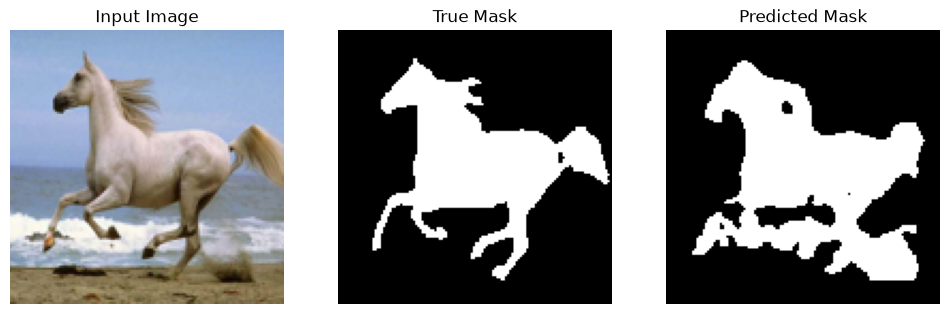

In [83]:
# NOTE from Hanan:
# This cell does not contain any  mistake.

predictions = model.predict(X_test)

index = 0

pred_mask = predictions[index].squeeze()
pred_mask_binary = (pred_mask > 0.4).astype(np.uint8)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(X_test[index])
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(y_test[index].squeeze(), cmap="gray")
plt.title("True Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(pred_mask_binary, cmap="gray")
plt.title("Predicted Mask")
plt.axis("off")

plt.show()